Isotropic
Class 1: 1000
Class 2: 1000
Diagonal
Class 1: 1000
Class 2: 1000
Full
Class 1: 1000
Class 2: 1000


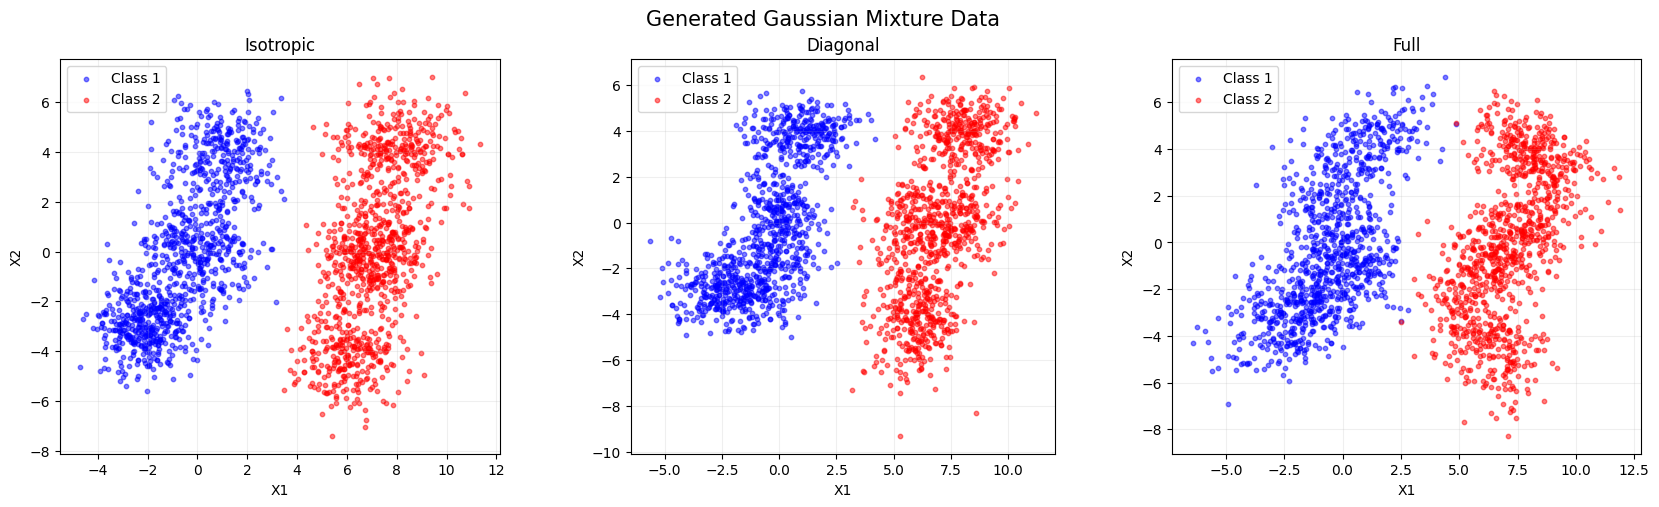

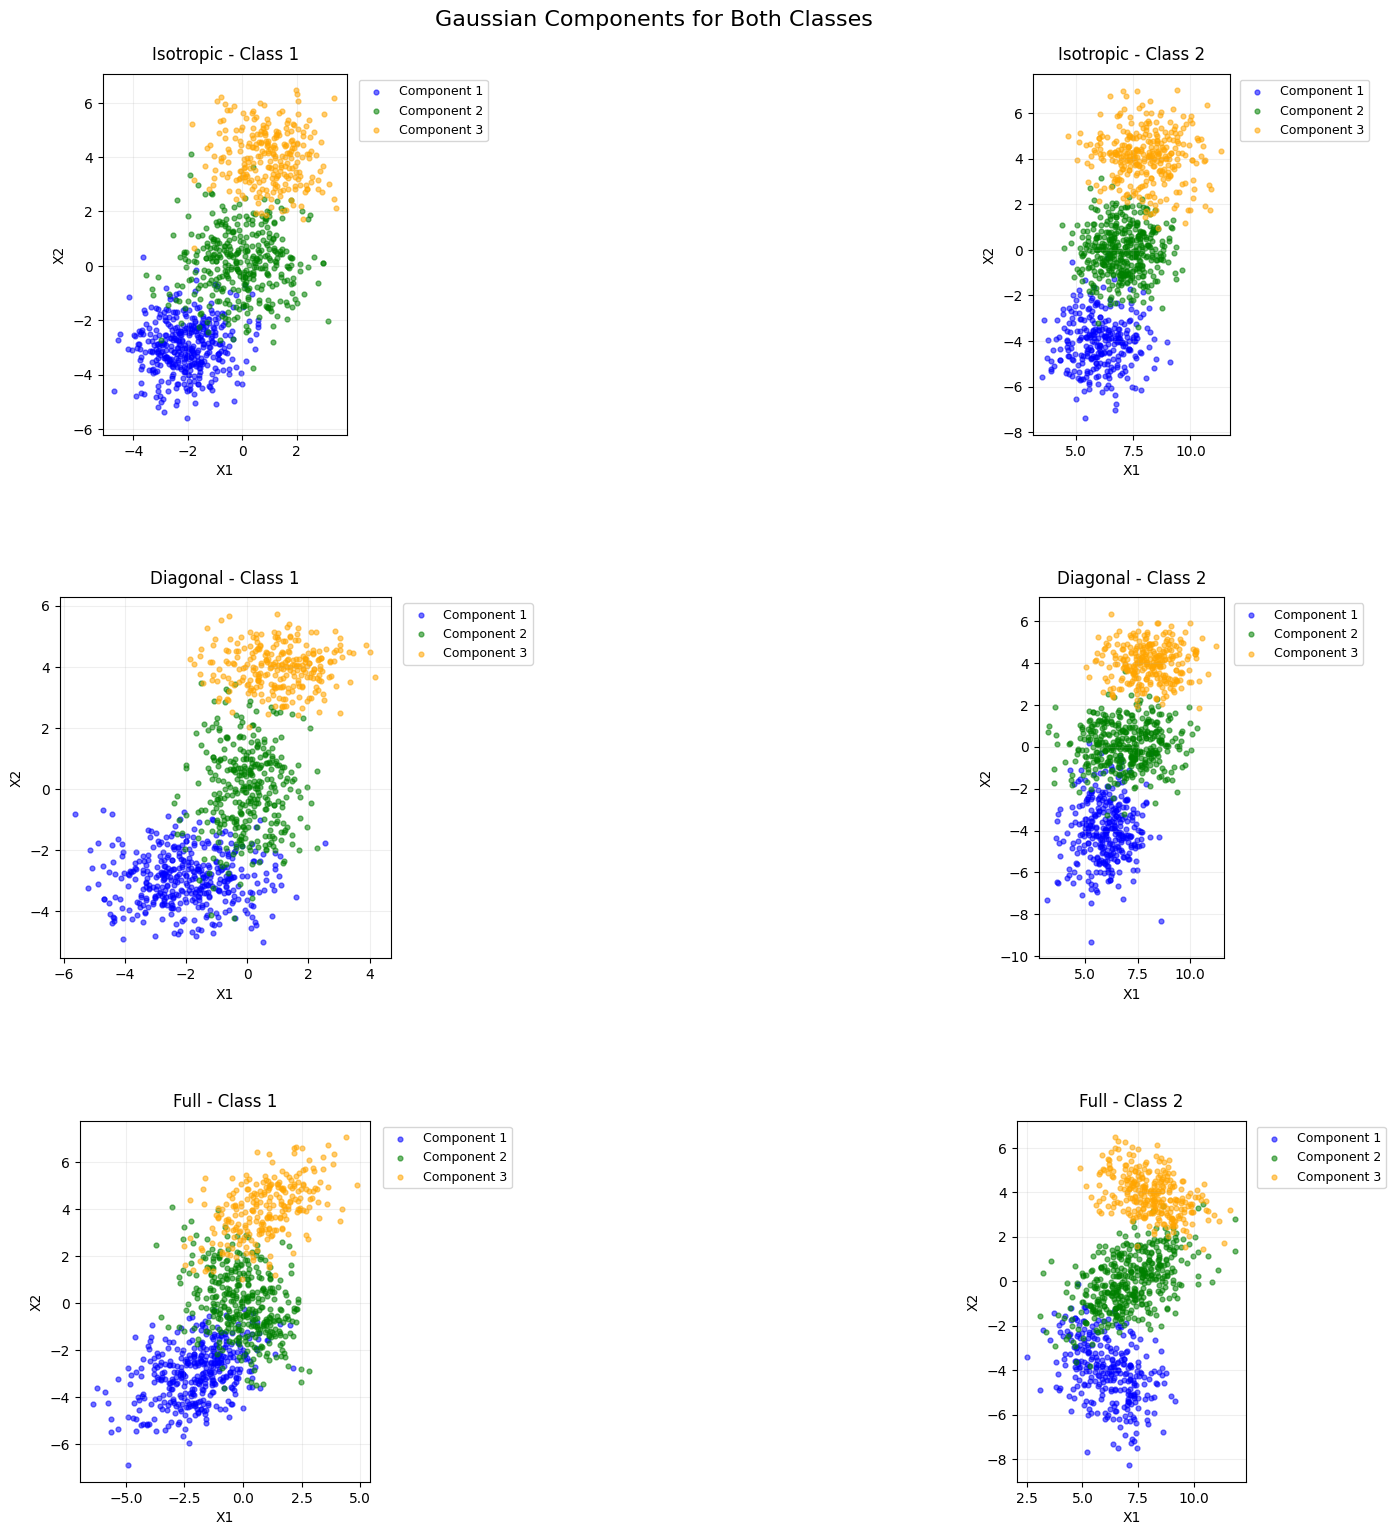

Isotropic Class 1 Train: 800 Test: 200 SSE: 1642.24 Iterations: 6
Isotropic Class 2 Train: 800 Test: 200 SSE: 1817.97 Iterations: 12
Diagonal Class 1 Train: 800 Test: 200 SSE: 1704.26 Iterations: 18
Diagonal Class 2 Train: 800 Test: 200 SSE: 1988.95 Iterations: 8
Full Class 1 Train: 800 Test: 200 SSE: 2441.25 Iterations: 23
Full Class 2 Train: 800 Test: 200 SSE: 2263.5 Iterations: 6


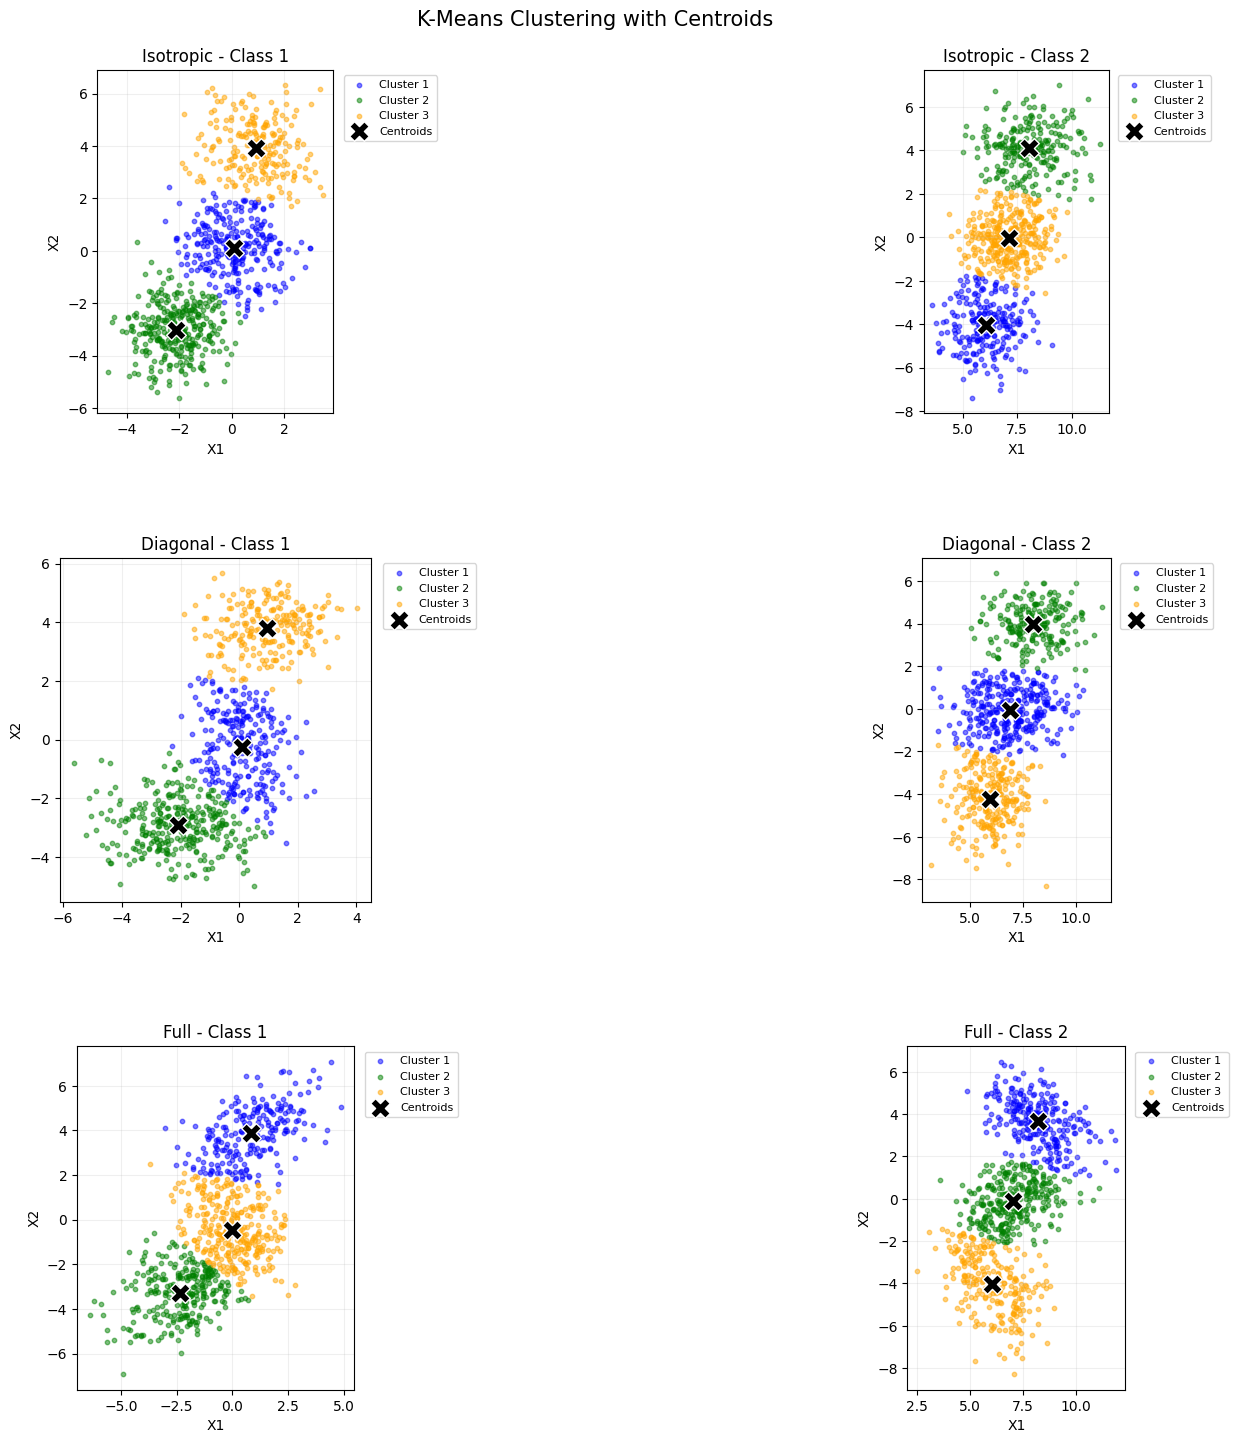

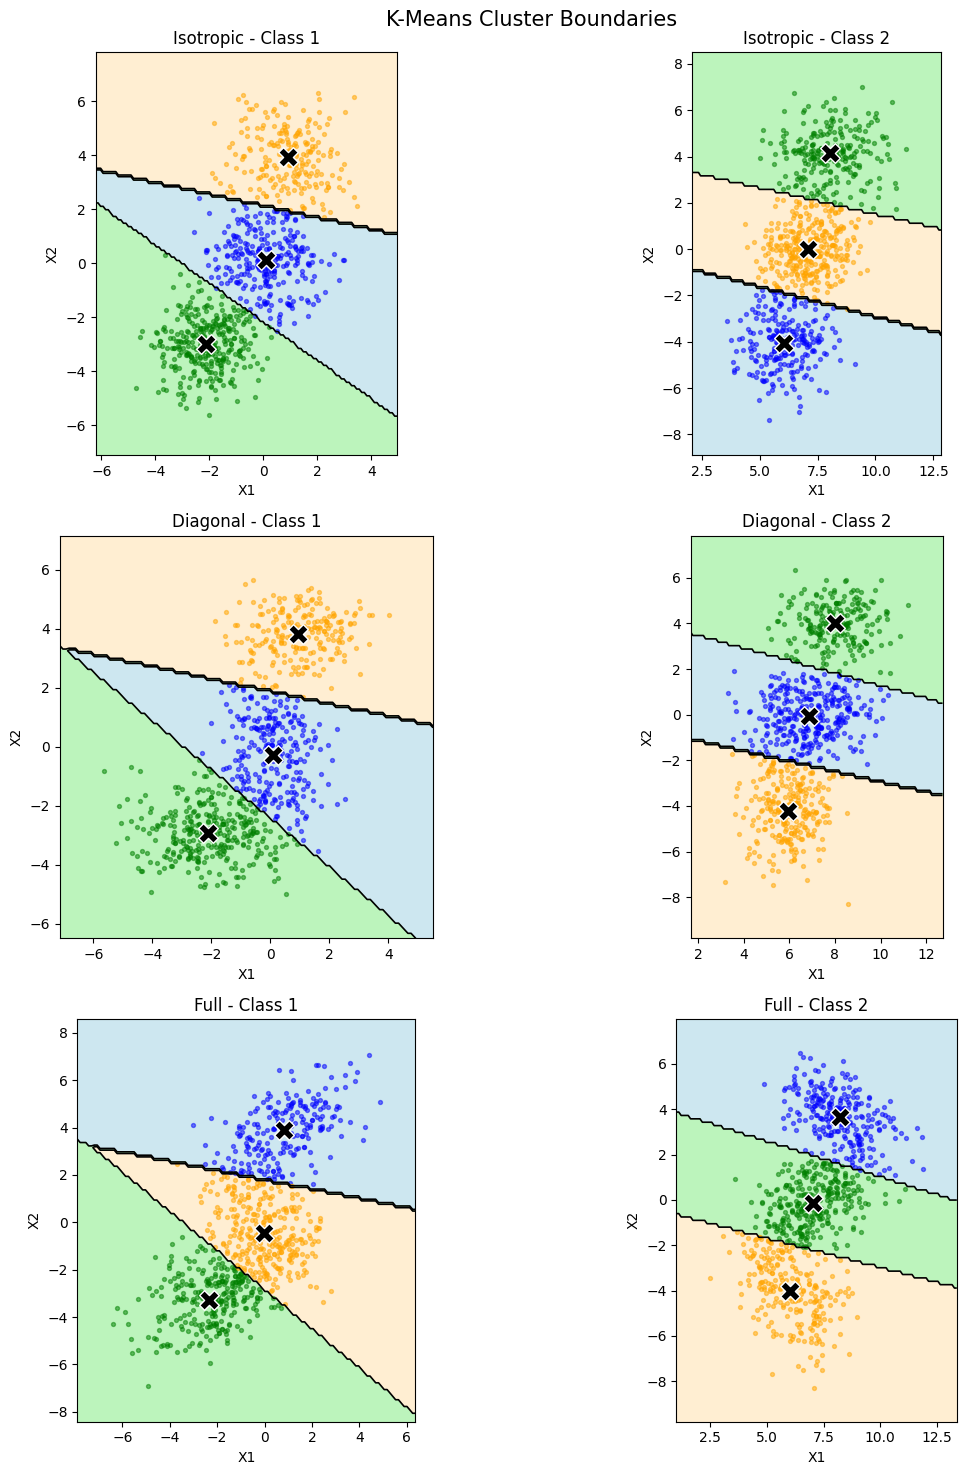


 Isotropic
Accuracy: 99.75%
Correct: 399 / 400
Confusion Matrix: [[199, 1], [0, 200]]

 Diagonal
Accuracy: 99.75%
Correct: 399 / 400
Confusion Matrix: [[200, 0], [1, 199]]

 Full
Accuracy: 99.75%
Correct: 399 / 400
Confusion Matrix: [[200, 0], [1, 199]]


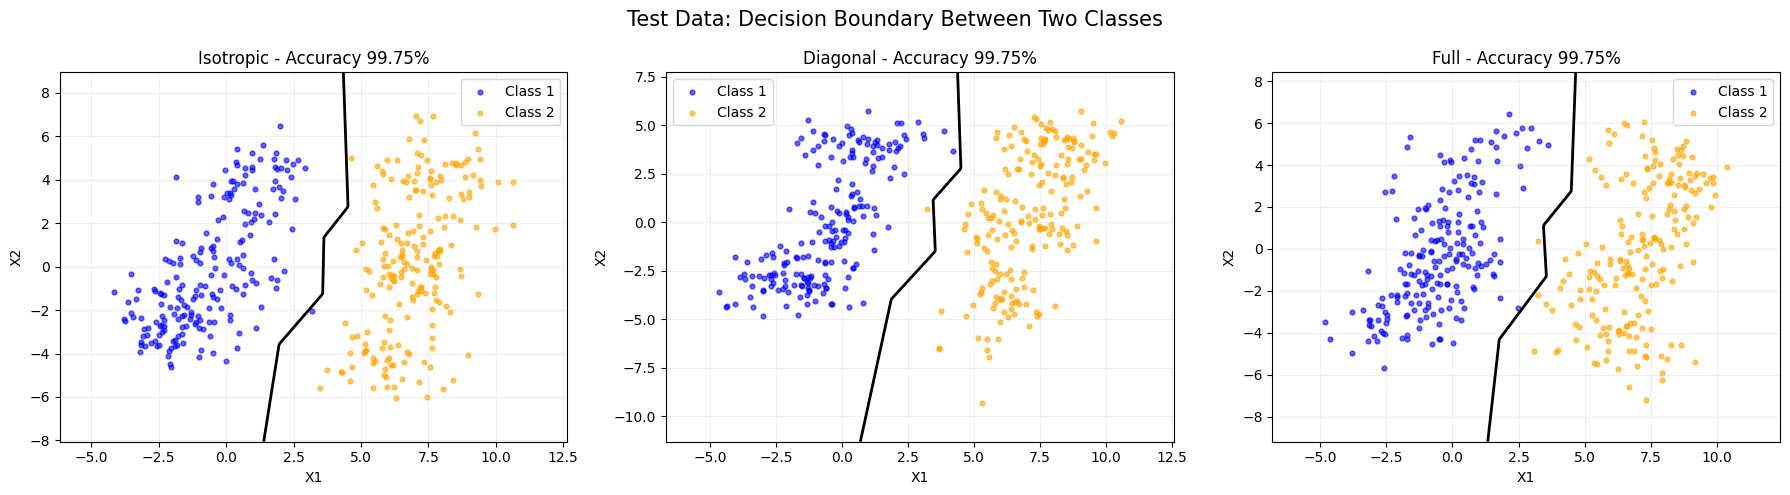

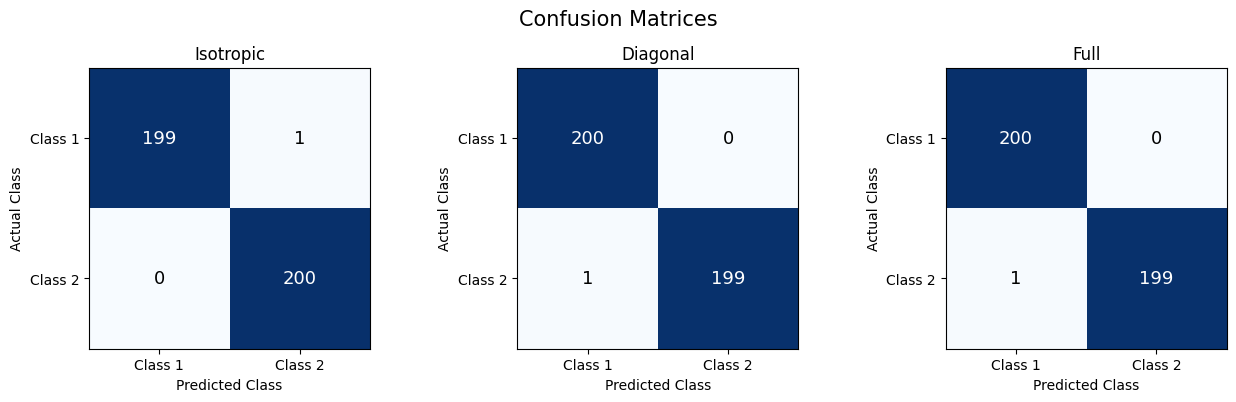


PRML ASSIGNMENT 6 - FINAL RESULTS

Covariance: Isotropic
Accuracy: 99.75%
Correct: 399 / 400
Class 1 SSE: 1642.24
Class 2 SSE: 1817.97
Iterations: 6 / 12
Confusion Matrix: [[199, 1], [0, 200]]

Covariance: Diagonal
Accuracy: 99.75%
Correct: 399 / 400
Class 1 SSE: 1704.26
Class 2 SSE: 1988.95
Iterations: 18 / 8
Confusion Matrix: [[200, 0], [1, 199]]

Covariance: Full
Accuracy: 99.75%
Correct: 399 / 400
Class 1 SSE: 2441.25
Class 2 SSE: 2263.5
Iterations: 23 / 6
Confusion Matrix: [[200, 0], [1, 199]]

OBSERVATIONS
1. Isotropic covariance produces circular components.
2. Diagonal covariance produces axis-aligned ellipses.
3. Full covariance can produce tilted ellipses.
4. K-Means forms three clusters for each class.
5. Centroids are learned using training data only.
6. Cluster boundaries form Voronoi regions.
7. Test classification uses minimum distortion.
8. Results depend on sampled data and initialization.
9. No random-number generation library was used.


In [1]:
import math
import matplotlib.pyplot as plt

# ============================================================
# PRML ASSIGNMENT 6
# Manual LCG + Box-Muller + Gaussian Mixture Model
# K-Means Clustering + Distortion-Based Classification
#
# Allowed libraries: math, matplotlib
# No random, numpy, sklearn, or built-in RNG
# ============================================================


# STEP 1: DEFINE PARAMETERS

N = 1000
K = 3
SEED = 42

weights1 = [0.40, 0.35, 0.25]
weights2 = [0.30, 0.40, 0.30]

means1 = [
    [-2, -3],
    [0, 0],
    [1, 4]
]

means2 = [
    [6, -4],
    [7, 0],
    [8, 4]
]


# STEP 2: MANUAL LINEAR CONGRUENTIAL GENERATOR

class ManualLCG:

    def __init__(self, seed=42):
        self.state = seed
        self.a = 1103515245
        self.c = 12345
        self.m = 2 ** 31

    def uniform(self):
        self.state = (
            self.a * self.state + self.c
        ) % self.m

        return self.state / self.m

    def integer_below(self, limit):
        if limit <= 0:
            raise ValueError("Limit must be positive")

        # Rejection sampling avoids modulo bias
        threshold = self.m - (self.m % limit)

        while True:
            self.state = (
                self.a * self.state + self.c
            ) % self.m

            if self.state < threshold:
                return self.state % limit


# STEP 3: MANUAL BOX-MULLER TRANSFORMATION

def box_muller(generator):

    u1 = generator.uniform()

    while u1 == 0:
        u1 = generator.uniform()

    u2 = generator.uniform()

    radius = math.sqrt(-2 * math.log(u1))
    angle = 2 * math.pi * u2

    z1 = radius * math.cos(angle)
    z2 = radius * math.sin(angle)

    return z1, z2


# STEP 4: SELECT GAUSSIAN COMPONENT

def select_component(weights, generator):

    r = generator.uniform()

    if r < weights[0]:
        return 0

    elif r < weights[0] + weights[1]:
        return 1

    else:
        return 2


# STEP 5: DEFINE COVARIANCE MATRICES

COVARIANCES = {

    "Isotropic": (
        [
            [[1, 0], [0, 1]],
            [[1.5, 0], [0, 1.5]],
            [[1.2, 0], [0, 1.2]]
        ],
        [
            [[1.2, 0], [0, 1.2]],
            [[1, 0], [0, 1]],
            [[1.5, 0], [0, 1.5]]
        ]
    ),

    "Diagonal": (
        [
            [[2, 0], [0, 0.8]],
            [[0.8, 0], [0, 2]],
            [[1.5, 0], [0, 0.6]]
        ],
        [
            [[1, 0], [0, 2]],
            [[2, 0], [0, 1]],
            [[1.5, 0], [0, 0.8]]
        ]
    ),

    "Full": (
        [
            [[2, 0.8], [0.8, 1.5]],
            [[1.5, -0.6], [-0.6, 2]],
            [[2, 1], [1, 1.5]]
        ],
        [
            [[1.5, -0.7], [-0.7, 2]],
            [[2, 0.9], [0.9, 1.5]],
            [[1.5, -0.5], [-0.5, 1]]
        ]
    )
}


# STEP 6: MANUAL COVARIANCE TRANSFORMATION

def transform_gaussian(z, mean, cov):

    a = cov[0][0]
    b = cov[0][1]
    d = cov[1][1]

    if cov[1][0] != b or a <= 0 or a*d-b*b <= 0:
        raise ValueError("Invalid covariance matrix")

    l11 = math.sqrt(a)
    l21 = b / l11
    l22 = math.sqrt(d - l21*l21)

    x1 = mean[0] + l11*z[0]
    x2 = mean[1] + l21*z[0] + l22*z[1]

    return [x1, x2]


# STEP 7: GENERATE GAUSSIAN MIXTURE DATA

def generate_gmm(n, weights, means, covariances, generator):

    points = []
    components = []

    for i in range(n):

        component = select_component(weights, generator)

        z = box_muller(generator)

        point = transform_gaussian(
            z,
            means[component],
            covariances[component]
        )

        points.append(point)
        components.append(component)

    return points, components


datasets = {}

for idx, (kind, (cov1, cov2)) in enumerate(
    COVARIANCES.items()
):

    data1, labels1 = generate_gmm(
        N, weights1, means1, cov1,
        ManualLCG(SEED + idx*100 + 1)
    )

    data2, labels2 = generate_gmm(
        N, weights2, means2, cov2,
        ManualLCG(SEED + idx*100 + 2)
    )

    datasets[kind] = {
        "all1": data1,
        "all2": data2,
        "components1": labels1,
        "components2": labels2
    }

    print(kind)
    print("Class 1:", len(data1))
    print("Class 2:", len(data2))


# STEP 8: PLOT GENERATED CLASSES

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, (kind, d) in zip(axes, datasets.items()):

    ax.scatter(
        [p[0] for p in d["all1"]],
        [p[1] for p in d["all1"]],
        color="blue",
        s=10,
        alpha=0.5,
        label="Class 1"
    )

    ax.scatter(
        [p[0] for p in d["all2"]],
        [p[1] for p in d["all2"]],
        color="red",
        s=10,
        alpha=0.5,
        label="Class 2"
    )

    ax.set_title(kind)
    ax.set_xlabel("X1")
    ax.set_ylabel("X2")
    ax.legend()
    ax.grid(alpha=0.2)
    ax.set_aspect("equal", adjustable="box")

plt.suptitle("Generated Gaussian Mixture Data", fontsize=15)
plt.tight_layout()
plt.show()


# ============================================================
# STEP 9: PLOT ORIGINAL GAUSSIAN COMPONENTS
# CORRECTED: LEGENDS OUTSIDE EACH GRAPH
# ============================================================

fig, axes = plt.subplots(3, 2, figsize=(16, 16))

colors = ["blue", "green", "orange"]

for row, (kind, d) in enumerate(datasets.items()):

    for cls in (1, 2):

        ax = axes[row][cls - 1]

        points = d[f"all{cls}"]
        labels = d[f"components{cls}"]

        for k in range(K):

            selected = [
                p for p, label in zip(points, labels)
                if label == k
            ]

            ax.scatter(
                [p[0] for p in selected],
                [p[1] for p in selected],
                color=colors[k],
                s=12,
                alpha=0.55,
                label=f"Component {k+1}"
            )

        ax.set_title(
            f"{kind} - Class {cls}",
            fontsize=12,
            pad=10
        )

        ax.set_xlabel("X1")
        ax.set_ylabel("X2")

        ax.grid(alpha=0.2)
        ax.set_aspect("equal", adjustable="box")

        # FIX: Put legend outside each graph
        ax.legend(
            loc="upper left",
            bbox_to_anchor=(1.02, 1),
            fontsize=9,
            frameon=True
        )

# Extra room for external legends
plt.subplots_adjust(
    left=0.07,
    right=0.96,
    top=0.94,
    bottom=0.06,
    wspace=0.75,
    hspace=0.45
)

plt.suptitle(
    "Gaussian Components for Both Classes",
    fontsize=16
)

plt.show()


# STEP 10: MANUAL SHUFFLING AND TRAIN-TEST SPLIT

def split_data(points, generator, fraction=0.8):

    shuffled = [p[:] for p in points]

    # Manual Fisher-Yates shuffling
    for i in range(len(shuffled)-1, 0, -1):

        j = generator.integer_below(i+1)

        shuffled[i], shuffled[j] = (
            shuffled[j], shuffled[i]
        )

    cutoff = int(len(shuffled) * fraction)

    return shuffled[:cutoff], shuffled[cutoff:]


# STEP 11: MANUAL SQUARED EUCLIDEAN DISTANCE

def squared_distance(p1, p2):

    return (
        (p1[0] - p2[0])**2 +
        (p1[1] - p2[1])**2
    )


def closest(point, centers):

    distances = [
        squared_distance(point, center)
        for center in centers
    ]

    return distances.index(min(distances))


# STEP 12: MANUAL K-MEANS ALGORITHM

def kmeans(points, k, generator, max_iter=100, tol=1e-6):

    available = list(range(len(points)))
    centers = []

    # Select distinct training points as initial centroids
    for i in range(k):

        position = generator.integer_below(len(available))
        index = available.pop(position)

        centers.append(points[index][:])

    for iteration in range(1, max_iter+1):

        groups = [[] for _ in range(k)]

        # Assign samples to nearest centroids
        for point in points:

            index = closest(point, centers)
            groups[index].append(point)

        updated = []

        # Recalculate centroids
        for j, group in enumerate(groups):

            if len(group) > 0:

                mean_x = sum(p[0] for p in group) / len(group)
                mean_y = sum(p[1] for p in group) / len(group)

                updated.append([mean_x, mean_y])

            else:
                updated.append(centers[j][:])

        # Calculate largest centroid movement
        shift = max(
            squared_distance(centers[j], updated[j])
            for j in range(k)
        )

        centers = updated

        if shift < tol * tol:
            break

    # Final cluster assignment
    labels = [
        closest(point, centers)
        for point in points
    ]

    # Calculate within-cluster distortion
    sse = sum(
        squared_distance(point, centers[label])
        for point, label in zip(points, labels)
    )

    return centers, labels, sse, iteration


# STEP 13: TRAIN K-MEANS FOR BOTH CLASSES

for idx, (kind, d) in enumerate(datasets.items()):

    for cls in (1, 2):

        train, test = split_data(
            d[f"all{cls}"],
            ManualLCG(5000 + idx*100 + cls)
        )

        centers, labels, sse, iterations = kmeans(
            train,
            K,
            ManualLCG(9000 + idx*100 + cls)
        )

        d[f"train{cls}"] = train
        d[f"test{cls}"] = test

        d[f"centers{cls}"] = centers
        d[f"cluster_labels{cls}"] = labels

        d[f"sse{cls}"] = sse
        d[f"iterations{cls}"] = iterations

        print(
            kind,
            "Class", cls,
            "Train:", len(train),
            "Test:", len(test),
            "SSE:", round(sse, 2),
            "Iterations:", iterations
        )


# STEP 14: PLOT K-MEANS CLUSTERS AND CENTROIDS

fig, axes = plt.subplots(3, 2, figsize=(14, 15))

for row, (kind, d) in enumerate(datasets.items()):

    for cls in (1, 2):

        ax = axes[row][cls-1]

        points = d[f"train{cls}"]
        centers = d[f"centers{cls}"]

        for k in range(K):

            selected = [
                p for p in points
                if closest(p, centers) == k
            ]

            ax.scatter(
                [p[0] for p in selected],
                [p[1] for p in selected],
                color=colors[k],
                s=10,
                alpha=0.5,
                label=f"Cluster {k+1}"
            )

        ax.scatter(
            [c[0] for c in centers],
            [c[1] for c in centers],
            marker="X",
            color="black",
            edgecolor="white",
            s=200,
            label="Centroids",
            zorder=5
        )

        ax.set_title(f"{kind} - Class {cls}")
        ax.set_xlabel("X1")
        ax.set_ylabel("X2")
        ax.grid(alpha=0.2)
        ax.set_aspect("equal", adjustable="box")

        # Legend outside to keep points visible
        ax.legend(
            loc="upper left",
            bbox_to_anchor=(1.02, 1),
            fontsize=8
        )

plt.subplots_adjust(
    left=0.07,
    right=0.96,
    top=0.94,
    bottom=0.06,
    wspace=0.80,
    hspace=0.42
)

plt.suptitle("K-Means Clustering with Centroids", fontsize=15)
plt.show()


# STEP 15: K-MEANS CLUSTER BOUNDARIES

def plot_cluster_boundary(ax, points, centers, title):

    x_min = min(p[0] for p in points) - 1.5
    x_max = max(p[0] for p in points) + 1.5

    y_min = min(p[1] for p in points) - 1.5
    y_max = max(p[1] for p in points) + 1.5

    size = 120

    xs = [
        x_min + j*(x_max-x_min)/(size-1)
        for j in range(size)
    ]

    ys = [
        y_min + i*(y_max-y_min)/(size-1)
        for i in range(size)
    ]

    region = [
        [closest([x, y], centers) for x in xs]
        for y in ys
    ]

    ax.contourf(
        xs, ys, region,
        levels=[-0.5, 0.5, 1.5, 2.5],
        colors=["lightblue", "lightgreen", "moccasin"],
        alpha=0.6
    )

    ax.contour(
        xs, ys, region,
        levels=[0.5, 1.5],
        colors="black",
        linewidths=1.2
    )

    for k in range(K):

        selected = [
            p for p in points
            if closest(p, centers) == k
        ]

        ax.scatter(
            [p[0] for p in selected],
            [p[1] for p in selected],
            s=8,
            color=colors[k],
            alpha=0.5
        )

    ax.scatter(
        [c[0] for c in centers],
        [c[1] for c in centers],
        marker="X",
        s=200,
        color="black",
        edgecolor="white",
        zorder=5
    )

    ax.set_title(title)
    ax.set_xlabel("X1")
    ax.set_ylabel("X2")
    ax.set_aspect("equal", adjustable="box")


fig, axes = plt.subplots(3, 2, figsize=(13, 15))

for row, (kind, d) in enumerate(datasets.items()):

    for cls in (1, 2):

        plot_cluster_boundary(
            axes[row][cls-1],
            d[f"train{cls}"],
            d[f"centers{cls}"],
            f"{kind} - Class {cls}"
        )

plt.suptitle("K-Means Cluster Boundaries", fontsize=15)
plt.tight_layout()
plt.show()


# STEP 16: DISTORTION-BASED CLASSIFIER

def class_distortion(point, centers):

    return min(
        squared_distance(point, center)
        for center in centers
    )


def classify(point, centers1, centers2):

    d1 = class_distortion(point, centers1)
    d2 = class_distortion(point, centers2)

    if d1 <= d2:
        return 1, d1, d2

    else:
        return 2, d1, d2


# STEP 17: TEST CLASSIFICATION AND ACCURACY

for kind, d in datasets.items():

    actual = (
        [1] * len(d["test1"]) +
        [2] * len(d["test2"])
    )

    test_points = d["test1"] + d["test2"]

    predicted = [
        classify(
            p,
            d["centers1"],
            d["centers2"]
        )[0]
        for p in test_points
    ]

    confusion = [
        [0, 0],
        [0, 0]
    ]

    for truth, prediction in zip(actual, predicted):
        confusion[truth-1][prediction-1] += 1

    correct = sum(
        a == b
        for a, b in zip(actual, predicted)
    )

    accuracy = 100 * correct / len(actual)

    d["confusion"] = confusion
    d["correct"] = correct
    d["accuracy"] = accuracy

    print("\n", kind)
    print("Accuracy:", f"{accuracy:.2f}%")
    print("Correct:", correct, "/", len(actual))
    print("Confusion Matrix:", confusion)


# STEP 18: TWO-CLASS DECISION BOUNDARIES

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (kind, d) in zip(axes, datasets.items()):

    test1 = d["test1"]
    test2 = d["test2"]

    all_points = test1 + test2

    x_min = min(p[0] for p in all_points) - 2
    x_max = max(p[0] for p in all_points) + 2

    y_min = min(p[1] for p in all_points) - 2
    y_max = max(p[1] for p in all_points) + 2

    size = 200

    xs = [
        x_min + j*(x_max-x_min)/(size-1)
        for j in range(size)
    ]

    ys = [
        y_min + i*(y_max-y_min)/(size-1)
        for i in range(size)
    ]

    differences = []

    for y in ys:

        row = []

        for x in xs:

            point = [x, y]

            d1 = class_distortion(
                point,
                d["centers1"]
            )

            d2 = class_distortion(
                point,
                d["centers2"]
            )

            row.append(d1-d2)

        differences.append(row)

    # Black equality boundary: D1 - D2 = 0
    ax.contour(
        xs,
        ys,
        differences,
        levels=[0],
        colors="black",
        linewidths=2
    )

    ax.scatter(
        [p[0] for p in test1],
        [p[1] for p in test1],
        color="blue",
        s=12,
        alpha=0.6,
        label="Class 1"
    )

    ax.scatter(
        [p[0] for p in test2],
        [p[1] for p in test2],
        color="orange",
        s=12,
        alpha=0.6,
        label="Class 2"
    )

    ax.set_title(
        f"{kind} - Accuracy {d['accuracy']:.2f}%"
    )

    ax.set_xlabel("X1")
    ax.set_ylabel("X2")
    ax.legend()
    ax.grid(alpha=0.2)

plt.suptitle(
    "Test Data: Decision Boundary Between Two Classes",
    fontsize=15
)

plt.tight_layout()
plt.show()


# STEP 19: CONFUSION MATRICES

fig, axes = plt.subplots(1, 3, figsize=(13, 4))

for ax, (kind, d) in zip(axes, datasets.items()):

    matrix = d["confusion"]

    ax.imshow(
        matrix,
        cmap="Blues",
        vmin=0,
        vmax=200
    )

    for i in range(2):

        for j in range(2):

            ax.text(
                j,
                i,
                str(matrix[i][j]),
                ha="center",
                va="center",
                color=(
                    "white"
                    if matrix[i][j] > 100
                    else "black"
                ),
                fontsize=13
            )

    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])

    ax.set_xticklabels(["Class 1", "Class 2"])
    ax.set_yticklabels(["Class 1", "Class 2"])

    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")
    ax.set_title(kind)

plt.suptitle("Confusion Matrices", fontsize=15)
plt.tight_layout()
plt.show()


# STEP 20: FINAL RESULTS AND OBSERVATIONS

print("\n" + "="*75)
print("PRML ASSIGNMENT 6 - FINAL RESULTS")
print("="*75)

for kind, d in datasets.items():

    print("\nCovariance:", kind)

    print("Accuracy:", f"{d['accuracy']:.2f}%")

    print("Correct:", d["correct"], "/ 400")

    print("Class 1 SSE:", round(d["sse1"], 2))
    print("Class 2 SSE:", round(d["sse2"], 2))

    print(
        "Iterations:",
        d["iterations1"],
        "/",
        d["iterations2"]
    )

    print("Confusion Matrix:", d["confusion"])

print("\nOBSERVATIONS")
print("="*75)

print("1. Isotropic covariance produces circular components.")
print("2. Diagonal covariance produces axis-aligned ellipses.")
print("3. Full covariance can produce tilted ellipses.")
print("4. K-Means forms three clusters for each class.")
print("5. Centroids are learned using training data only.")
print("6. Cluster boundaries form Voronoi regions.")
print("7. Test classification uses minimum distortion.")
print("8. Results depend on sampled data and initialization.")
print("9. No random-number generation library was used.")